# EDA: Bike Sharing

Findings that change the data preparation (section 2) are marked with **↺**.

| Iteration | Question | Data |
|:--|:--|:--|
| 1 | Is the data valid? | whole file (validity checks only, nothing is learned) |
| 2 | How are the target and the features distributed? | training set |
| 3 | Are the extreme values errors or real events? | training set |
| 4 | How do time and weather drive the rentals? | training set |
| 5 | Which features are redundant, informative or leaking? | training set |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 0. First look

In [2]:
df = pd.read_csv("data/bike_sharing.csv", parse_dates=["datetime"])
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns | period: {df['datetime'].min()} to {df['datetime'].max()}")
df.head()

17,520 rows x 13 columns | period: 2024-10-01 00:00:00 to 2026-09-30 23:00:00


,datetime,casual,member,rentals,temperature,feels_like,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,holiday
0,2024-10-01 00:00:00,47,89,136,18.1,19.5,96,0.2,0.0,8.6,100,51,NaN
1,2024-10-01 01:00:00,18,30,48,18.2,19.6,96,0.1,0.0,8.9,100,51,NaN
2,2024-10-01 02:00:00,14,17,31,18.2,19.2,94,0.0,0.0,10.3,100,3,NaN
3,2024-10-01 03:00:00,6,9,15,17.9,18.6,93,0.0,0.0,11.7,100,3,NaN
4,2024-10-01 04:00:00,7,20,27,17.6,18.1,93,0.1,0.0,12.4,100,51,NaN


## 1. Iteration 1: Data quality (whole file)

**Question:** Are there missing, duplicated or invalid values?

In [3]:
print("Missing values:", df.isna().sum()[lambda s: s > 0].to_dict())
print("Duplicated timestamps:", df["datetime"].duplicated().sum())
expected = pd.date_range(df["datetime"].min(), df["datetime"].max(), freq="h")
print("Missing hours:", len(expected.difference(df["datetime"])))

# `holiday` is only filled on public holidays: does every holiday cover whole days?
holiday_rows = df.dropna(subset=["holiday"])
hours_per_day = holiday_rows.groupby(holiday_rows["datetime"].dt.date).size()
print("Holiday days:", len(hours_per_day), "| hours per holiday day:", hours_per_day.unique())

Missing values: {'holiday': 16944}
Duplicated timestamps: 0
Missing hours: 0
Holiday days: 24 | hours per holiday day: [24]


In [4]:
# Logical and physical rules every row must respect: number of rows that break each rule
valid_codes = [0, 1, 2, 3, 51, 53, 55, 61, 63, 65, 71, 73, 75]
rules = {
    "rentals == casual + member": df["rentals"] == df["casual"] + df["member"],
    "casual, member, rentals >= 0": (df[["casual", "member", "rentals"]] >= 0).all(axis=1),
    "humidity in [0, 100] %": df["humidity"].between(0, 100),
    "cloud_cover in [0, 100] %": df["cloud_cover"].between(0, 100),
    "precipitation, snowfall, wind_speed >= 0": (df[["precipitation", "snowfall", "wind_speed"]] >= 0).all(axis=1),
    "temperature in [-30, 45] °C": df["temperature"].between(-30, 45),
    "|feels_like - temperature| <= 15 °C": (df["feels_like"] - df["temperature"]).abs() <= 15,
    "weather_code is a documented WMO code": df["weather_code"].isin(valid_codes),
    "snowfall > 0 implies precipitation > 0": ~((df["snowfall"] > 0) & (df["precipitation"] == 0)),
}
pd.Series({rule: int((~ok).sum()) for rule, ok in rules.items()}, name="violations").to_frame()

,violations
rentals == casual + member,0
"casual, member, rentals >= 0",0
"humidity in [0, 100] %",0
"cloud_cover in [0, 100] %",0
"precipitation, snowfall, wind_speed >= 0",0
"temperature in [-30, 45] °C",0
|feels_like - temperature| <= 15 °C,0
weather_code is a documented WMO code,0
snowfall > 0 implies precipitation > 0,0


**Finding:** No duplicates, no gaps (one row per hour), all values valid. `holiday` is only *structurally* missing (empty on non-holidays; each holiday covers 24 h) → **↺** flag `is_holiday`.

**Next question:** Washington, D.C. uses daylight saving time, yet there is exactly one row per hour. How were the non-existent hour (02:00 in March) and the doubled hour (01:00 in November) filled?

In [5]:
def nth_sunday(year, month, n):
    """Date of the n-th Sunday of a month."""
    days = pd.date_range(f"{year}-{month:02d}-01", periods=31, freq="D")
    sundays = days[(days.month == month) & (days.dayofweek == 6)]
    return sundays[n - 1]


years = range(df["datetime"].dt.year.min(), df["datetime"].dt.year.max() + 1)
spring_forward = [nth_sunday(y, 3, 2) + pd.Timedelta(hours=2) for y in years]  # 02:00 does not exist
fall_back = [nth_sunday(y, 11, 1) + pd.Timedelta(hours=1) for y in years]      # 01:00 happens twice

dst_hours = df[df["datetime"].isin(spring_forward + fall_back)].copy()
dst_hours["change"] = np.where(dst_hours["datetime"].dt.month == 3, "spring forward", "fall back")

# Reference: median rentals in the same hour on the two Sundays before and after
dst_hours["median_other_sundays"] = dst_hours["datetime"].map(
    lambda ts: df.loc[df["datetime"].isin([ts + pd.Timedelta(weeks=w) for w in (-2, -1, 1, 2)]), "rentals"].median()
)
dst_hours[["datetime", "change", "rentals", "median_other_sundays"]]

,datetime,change,rentals,median_other_sundays
793,2024-11-03 01:00:00,fall back,645,371.5
3818,2025-03-09 02:00:00,spring forward,0,162.0
9529,2025-11-02 01:00:00,fall back,582,341.0
12554,2026-03-08 02:00:00,spring forward,0,196.0


**Finding:** These hours are **corrupt** although they pass all range checks: spring-forward 02:00 has **0 rentals**, fall-back 01:00 has about **twice** the usual rentals (two clock hours). → **↺** drop them with a calendar-only rule, which can also be applied to the test set.

## 2. Train-test split and data preparation

From here on, only the training set is explored. Same split as in `01_bike_sharing_project.ipynb`.

Every manual change is a **function**, so that exactly the same changes can be applied to `df_test` in step 8 of the project. Transformations that learn from the data (scaling, one-hot encoding, log target) belong in the model `Pipeline`, not here. The preparation grew with the iterations: each step goes back to a **↺** finding.

In [6]:
# Same split as in 01_bike_sharing_project.ipynb; df_test is not used in this notebook
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
print("Train:", df_train.shape, "| Test:", df_test.shape)

Train: (14016, 13) | Test: (3504, 13)


### 2.1 Remove the corrupt DST hours (↺ iteration 1)

- **Spring forward, 02:00:** the hour did not exist, its 0 rentals are not a measurement.
- **Fall back, 01:00:** two clock hours in one row; halving would only be a guess.

The rule only uses the calendar, not the rentals, so it is fair to apply it to the test set as well.

In [7]:
def dst_artifact_hours(data):
    """Boolean mask of the hours that are corrupt because of the clock change (rule from iteration 1)."""
    years = data["datetime"].dt.year.unique()
    spring_forward = [nth_sunday(y, 3, 2) + pd.Timedelta(hours=2) for y in years]  # 02:00 does not exist
    fall_back = [nth_sunday(y, 11, 1) + pd.Timedelta(hours=1) for y in years]      # 01:00 counts two hours
    return data["datetime"].isin(spring_forward + fall_back)


def remove_dst_artifacts(data):
    """Drop the non-existent 02:00 on spring-forward Sundays and the doubled 01:00 on fall-back Sundays."""
    return data[~dst_artifact_hours(data)].copy()


# Which of the corrupt hours are in the training set?
removed = df_train[dst_artifact_hours(df_train)].sort_values("datetime")
print(f"Corrupt DST hours in the training set: {len(removed)}")
removed[["datetime", "casual", "member", "rentals"]]

Corrupt DST hours in the training set: 3


,datetime,casual,member,rentals
793,2024-11-03 01:00:00,285,360,645
3818,2025-03-09 02:00:00,0,0,0
12554,2026-03-08 02:00:00,0,0,0


### 2.2 Derived features

| New column | Derived from | Why |
|:--|:--|:--|
| `hour`, `weekday`, `month` | `datetime` | Daily pattern and season (iteration 4); a model cannot use a timestamp directly |
| `is_holiday` | `holiday` | `holiday` is a text column, empty on 97 % of the days (iteration 1) |
| `day_type` | `weekday`, `is_holiday` | Working days, weekends and holidays have different daily patterns (iteration 4) |
| `weather_group` | `weather_code` | Several codes are very rare (iteration 2); codes 0 to 2 have the same effect on rentals (iteration 4) |

In [8]:
# WMO weather codes grouped by their effect on rentals (codes 0 to 2 behave alike, see iteration 4)
WEATHER_GROUPS = {
    0: "clear", 1: "clear", 2: "clear",
    3: "overcast",
    51: "drizzle", 53: "drizzle", 55: "drizzle",
    61: "rain", 63: "rain", 65: "rain",
    71: "snow", 73: "snow", 75: "snow",
}


def add_features(data):
    """Derive calendar features from `datetime` and `holiday`, and group the weather codes."""
    data = data.copy()
    data["hour"] = data["datetime"].dt.hour
    data["weekday"] = data["datetime"].dt.dayofweek  # 0 = Monday, 6 = Sunday
    data["month"] = data["datetime"].dt.month
    data["is_holiday"] = data["holiday"].notna().astype(int)
    data["day_type"] = np.select(
        [data["is_holiday"] == 1, data["weekday"] >= 5],
        ["holiday", "weekend"],
        default="working day",
    )
    data["weather_group"] = data["weather_code"].map(WEATHER_GROUPS)
    return data

### 2.3 One function for all manual changes

`prepare_data` combines the steps and drops the columns that must not become features:

- `casual` and `member` add up to the target (**leakage**, iteration 5);
- `holiday` is replaced by `is_holiday` and `day_type`.

`datetime` stays for later analyses (e.g. residuals in step 8) and is left out when building `X_train`. Redundant features such as `feels_like` are a modelling decision and are not dropped here.

In [9]:
LEAKAGE_COLUMNS = ["casual", "member"]


def prepare_data(data):
    """All manual changes to the raw data. Apply it unchanged to df_test in step 8."""
    data = remove_dst_artifacts(data)
    data = add_features(data)
    return data.drop(columns=LEAKAGE_COLUMNS + ["holiday"])


df_train_prepared = prepare_data(df_train)
print("Before:", df_train.shape, "| after:", df_train_prepared.shape)
df_train_prepared.head()

Before: (14016, 13) | after: (14013, 16)


,datetime,rentals,temperature,feels_like,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,hour,weekday,month,is_holiday,day_type,weather_group
17440,2026-09-27 16:00:00,1035,16.7,15.2,87,0.5,0.0,20.3,100,53,16,6,9,0,weekend,drizzle
16867,2026-09-03 19:00:00,1826,30.4,35.1,67,0.0,0.0,7.7,47,1,19,3,9,0,working day,clear
14851,2026-06-11 19:00:00,1661,31.7,35.8,60,0.0,0.0,9.1,97,3,19,3,6,0,working day,overcast
5446,2025-05-15 22:00:00,1001,20.8,23.7,93,0.0,0.0,5.4,7,0,22,3,5,0,working day,clear
6025,2025-06-09 01:00:00,114,19.7,22.7,99,0.0,0.0,3.5,100,3,1,0,6,0,working day,overcast


In [10]:
# Sanity checks of the prepared training set
assert not dst_artifact_hours(df_train_prepared).any(), "corrupt DST hours left"
assert not set(LEAKAGE_COLUMNS) & set(df_train_prepared.columns), "leaking columns left"
assert df_train_prepared.notna().all().all(), "missing values left"
print("All checks passed.")

df_train_prepared.dtypes.to_frame("dtype").T

All checks passed.


,datetime,rentals,temperature,feels_like,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,hour,weekday,month,is_holiday,day_type,weather_group
dtype,datetime64[us],int64,float64,float64,int64,float64,float64,float64,int64,int64,int32,int32,int32,int64,str,str


For the exploration we use the same steps but **keep** `casual`, `member` and `holiday`, so that we can still look at them. They are not used as features.

In [11]:
# Exploration copy of the training set: same preparation, but casual, member and holiday are kept
train = add_features(remove_dst_artifacts(df_train))
day_types = ["working day", "weekend", "holiday"]
weather_num = ["temperature", "feels_like", "humidity", "precipitation", "snowfall", "wind_speed", "cloud_cover"]
num_cols = ["rentals", "casual", "member"] + weather_num

## 3. Iteration 2: Distributions

**Question:** How are the target and the features distributed?

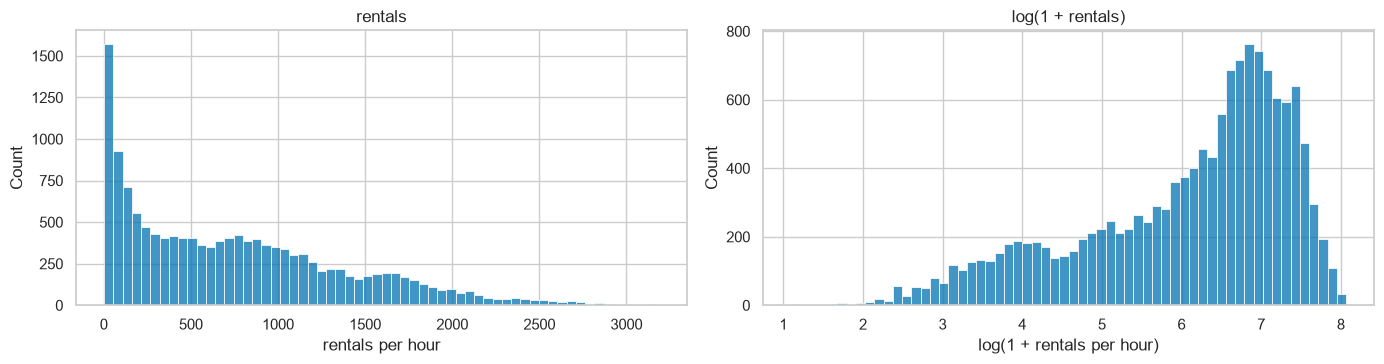

,rentals,casual,member
mean,753.44,218.78,534.66
median,639.00,158.00,464.00
min,2.00,0.00,0.00
max,3188.00,1593.00,2465.00
skew,0.85,1.30,0.93


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
sns.histplot(train["rentals"], bins=60, ax=axes[0])
axes[0].set(title="rentals", xlabel="rentals per hour")
sns.histplot(np.log1p(train["rentals"]), bins=60, ax=axes[1])
axes[1].set(title="log(1 + rentals)", xlabel="log(1 + rentals per hour)")
plt.tight_layout()
plt.show()

train[["rentals", "casual", "member"]].agg(["mean", "median", "min", "max", "skew"]).round(2)

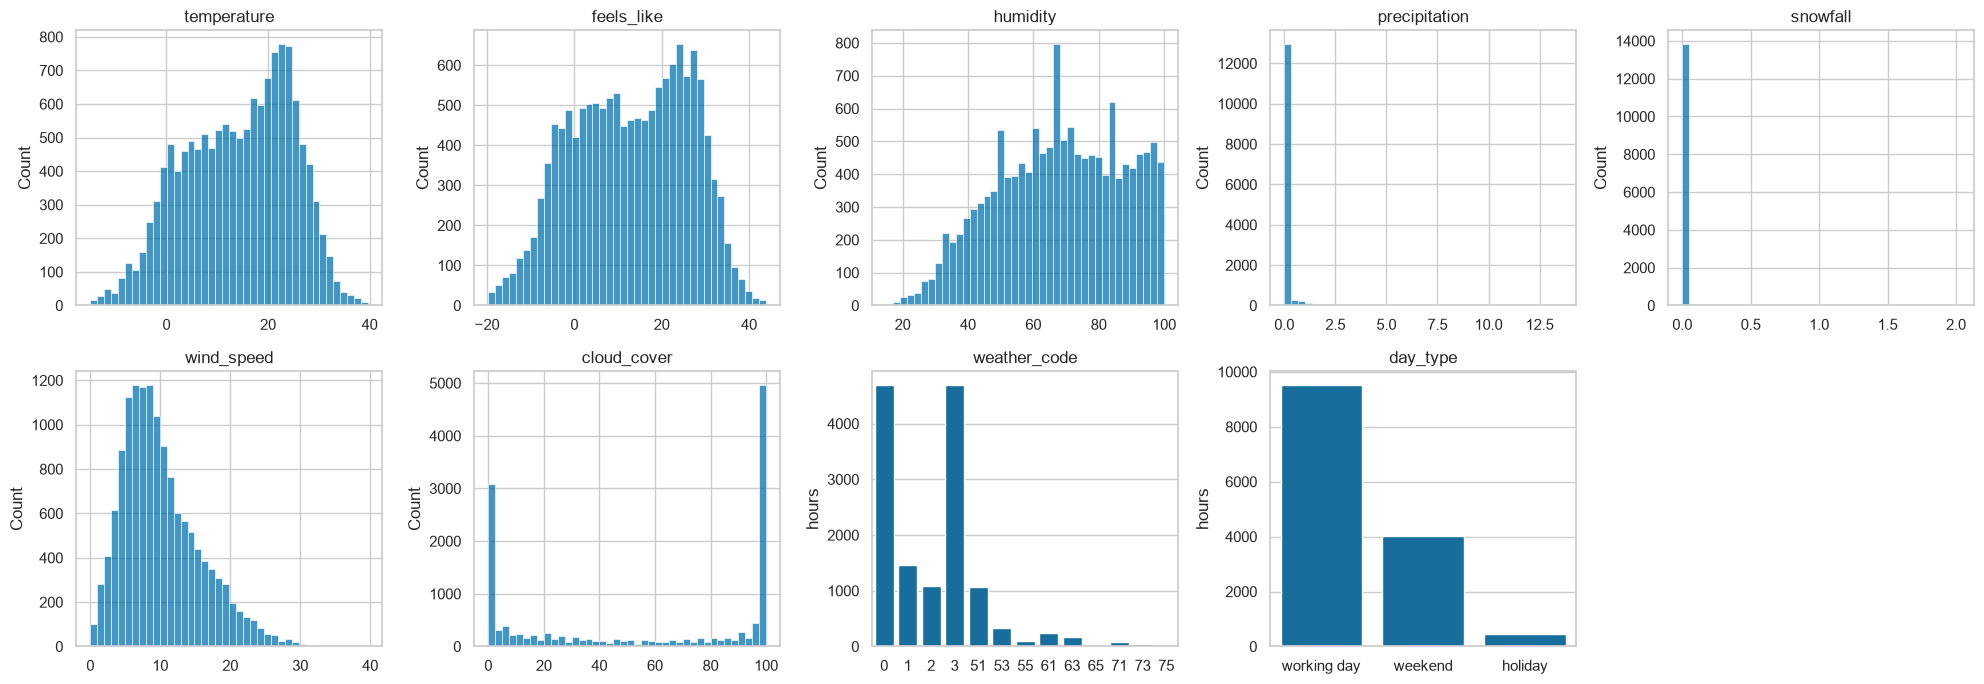

Share of hours equal to 0 (%): {'temperature': 0.1, 'feels_like': 0.2, 'humidity': 0.0, 'precipitation': 85.2, 'snowfall': 98.9, 'wind_speed': 0.0, 'cloud_cover': 17.2}


In [13]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.flat, weather_num):
    sns.histplot(train[col], bins=40, ax=ax)
    ax.set(title=col, xlabel="")
sns.countplot(data=train, x="weather_code", ax=axes.flat[7])
axes.flat[7].set(title="weather_code", xlabel="", ylabel="hours")
sns.countplot(data=train, x="day_type", order=day_types, ax=axes.flat[8])
axes.flat[8].set(title="day_type", xlabel="", ylabel="hours")
axes.flat[9].set_visible(False)
plt.tight_layout()
plt.show()

print("Share of hours equal to 0 (%):", ((train[weather_num] == 0).mean() * 100).round(1).to_dict())

**Finding:**
- `rentals` is **right-skewed** (≈0 at night, > 3,000 at rush hour; mean > median) → consider training on `log1p(rentals)`; choose RMSE vs. MAE deliberately.
- `precipitation` and `snowfall` are **zero-inflated**, `cloud_cover` is U-shaped.
- Heavy rain (65) and snow (71 to 75) are **rare**, holidays only ≈3 % of the hours → **↺** group the codes into `weather_group`.

**Next question:** Are the extreme values errors?

## 4. Iteration 3: Outliers

**Question:** Which values are unusual, and are they errors or real events? First attempt: the global IQR rule.

In [14]:
def iqr_outliers(s, k=1.5):
    """Boolean mask of values outside [Q1 - k*IQR, Q3 + k*IQR]."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)


outlier_mask = train[num_cols].apply(iqr_outliers)
pd.DataFrame({
    "share_outliers_%": outlier_mask.mean() * 100,
    "Q1": train[num_cols].quantile(0.25),
    "Q3": train[num_cols].quantile(0.75),
    "max": train[num_cols].max(),
}).round(2)

,share_outliers_%,Q1,Q3,max
rentals,0.91,187.0,1142.0,3188.00
casual,2.92,47.0,320.0,1593.00
member,1.21,134.0,813.0,2465.00
temperature,0.00,5.8,22.7,39.70
feels_like,0.00,2.3,24.1,43.90
humidity,0.00,53.0,84.0,100.00
precipitation,14.83,0.0,0.0,13.60
snowfall,1.11,0.0,0.0,2.03
wind_speed,1.87,6.0,13.3,39.70
cloud_cover,0.00,5.0,100.0,100.00


**Finding:** The IQR rule flags the **busy hours** and, since Q1 = Q3 = 0, **every hour with rain or snow**. A global rule ignores context: 1,500 rentals are a lot at 3:00 and normal at 17:00.

**Refined question:** Which hours deviate strongly from *comparable* hours (same `hour` and `day_type`)? → robust z-score (distance from the group median in units of the MAD).

In [15]:
group = train.groupby(["hour", "day_type"])["rentals"]
group_median = group.transform("median")
group_mad = group.transform(lambda s: (s - s.median()).abs().median())
robust_z = (train["rentals"] - group_median) / (1.4826 * group_mad)

print(f"|robust z| > 3.5: {int((robust_z.abs() > 3.5).sum())} of {len(train)} hours "
      f"({int((robust_z > 3.5).sum())} far more, {int((robust_z < -3.5).sum())} far fewer rentals than usual)")

show_cols = ["datetime", "day_type", "rentals", "group_median", "robust_z", "temperature", "snowfall", "holiday"]
unusual = train.assign(group_median=group_median, robust_z=robust_z.round(2))[show_cols]
pd.concat([unusual.nlargest(5, "robust_z"), unusual.nsmallest(5, "robust_z")])

|robust z| > 3.5: 65 of 14013 hours (44 far more, 21 far fewer rentals than usual)


,datetime,day_type,rentals,group_median,robust_z,temperature,snowfall,holiday
17261,2026-09-20 05:00:00,weekend,378,67.0,12.34,21.8,0.00,NaN
15409,2026-07-05 01:00:00,weekend,1596,309.0,11.13,24.8,0.00,NaN
14929,2026-06-15 01:00:00,working day,372,59.0,10.56,22.7,0.00,NaN
17262,2026-09-20 06:00:00,weekend,708,146.0,9.03,21.5,0.00,NaN
13398,2026-04-12 06:00:00,weekend,676,146.0,8.51,9.4,0.00,NaN
2337,2025-01-06 09:00:00,working day,32,984.5,-4.40,-3.6,1.19,NaN
11577,2026-01-26 09:00:00,working day,35,984.5,-4.39,-4.9,0.00,NaN
11601,2026-01-27 09:00:00,working day,71,984.5,-4.22,-15.0,0.00,NaN
2361,2025-01-07 09:00:00,working day,105,984.5,-4.06,-6.0,0.00,NaN
11556,2026-01-25 12:00:00,weekend,50,1495.0,-3.93,-7.7,0.07,NaN


**Finding:** Two kinds of unusual hours, both **real events, not errors** → keep them:
- **Far more rentals:** nights and early mornings around weekends and holidays (e.g. the night after Independence Day 2026). Not explained by the weather.
- **Far fewer rentals:** during and after **snowfall** and in severe cold (January 2025, after the snowstorm of 2026-01-25). Partly learnable from the temperature; snow cover is not in the data.

The only true data errors remain the DST hours from iteration 1.

**Next question:** How do time and weather drive the rentals?

## 5. Iteration 4: Rentals over time and with the weather

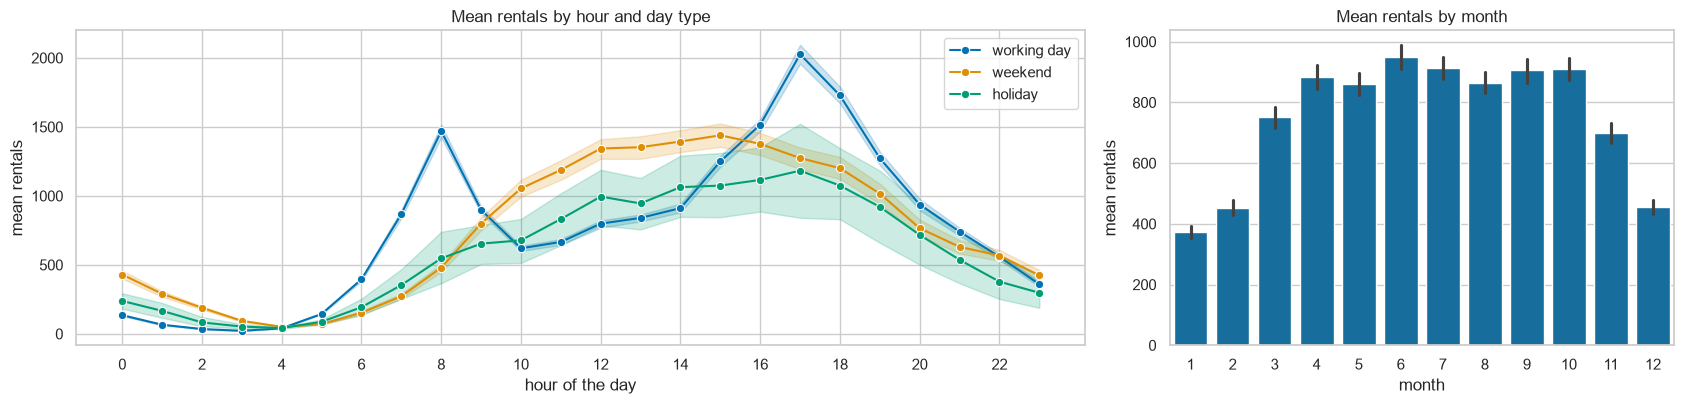

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw={"width_ratios": [2, 1]})
sns.lineplot(data=train, x="hour", y="rentals", hue="day_type", hue_order=day_types, marker="o", ax=axes[0])
axes[0].set(title="Mean rentals by hour and day type", xlabel="hour of the day", ylabel="mean rentals")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(title="")
sns.barplot(data=train, x="month", y="rentals", ax=axes[1])
axes[1].set(title="Mean rentals by month", ylabel="mean rentals")
plt.tight_layout()
plt.show()

**Finding:** Working days have two **commuter peaks** (8:00, 17:00 to 18:00), weekends and holidays one midday hump → non-linear `hour` effect with a **`hour` × `day_type` interaction** (**↺** `day_type`). Strong **season**: low in January/February, high from late spring to autumn.

**Next question:** How much does the weather add? (Weather codes only in daytime hours 7:00 to 20:00, to separate them from the time of day.)

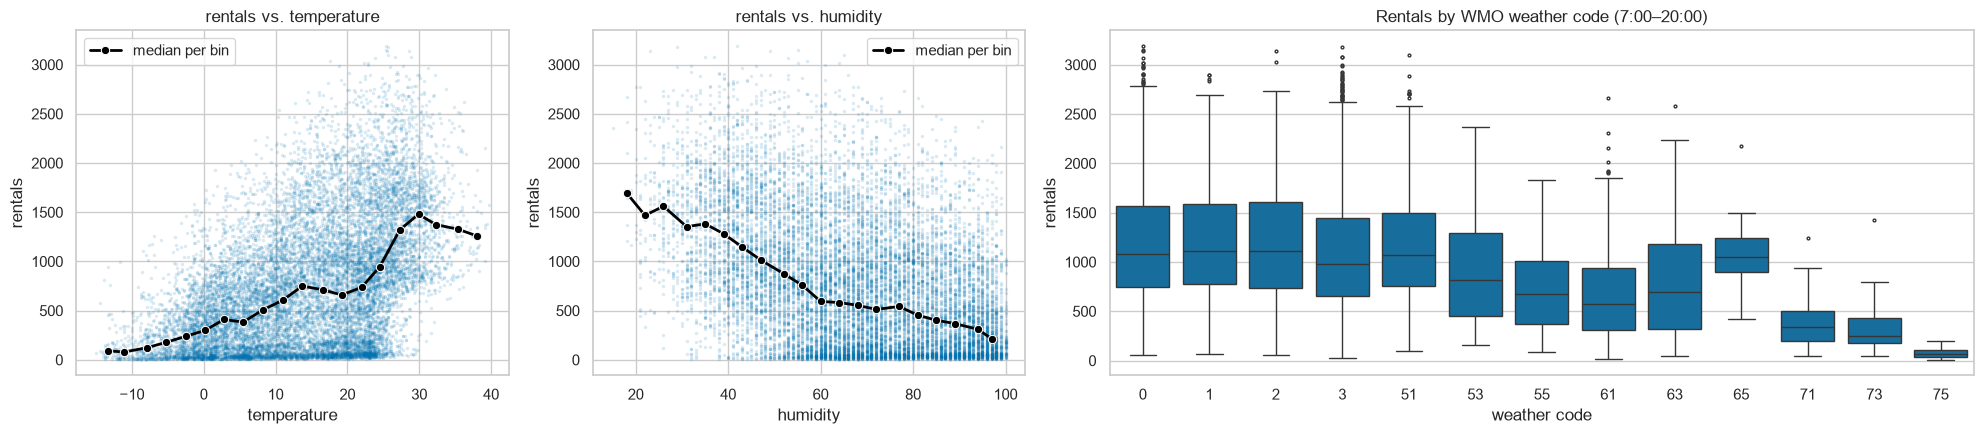

weather_group,clear,overcast,drizzle,rain,snow
count,4094.0,2778.0,968.0,251.0,110.0
median,1097.0,982.5,988.5,663.0,246.5


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5), gridspec_kw={"width_ratios": [1, 1, 2]})
for ax, col in zip(axes, ["temperature", "humidity"]):
    sns.scatterplot(data=train, x=col, y="rentals", s=6, alpha=0.15, linewidth=0, ax=ax)
    binned = train.groupby(pd.cut(train[col], bins=20), observed=True).agg(x=(col, "median"), y=("rentals", "median"))
    sns.lineplot(data=binned, x="x", y="y", color="black", lw=2, marker="o", ax=ax, label="median per bin")
    ax.set(title=f"rentals vs. {col}", xlabel=col, ylabel="rentals")

daytime = train[train["hour"].between(7, 20)]
sns.boxplot(data=daytime, x="weather_code", y="rentals", fliersize=2, ax=axes[2])
axes[2].set(title="Rentals by WMO weather code (7:00–20:00)", xlabel="weather code", ylabel="rentals")
plt.tight_layout()
plt.show()

weather_groups = ["clear", "overcast", "drizzle", "rain", "snow"]
daytime.groupby("weather_group")["rentals"].agg(["count", "median"]).reindex(weather_groups).T

**Finding:**
- **Temperature** has the clearest weather effect, non-linear (flattens at the highest temperatures); **humidity** is negative.
- Codes 0 to 2 behave alike, drizzle is close to overcast, **rain** lowers the median by ≈40 %, **snow** by ≈80 % → **↺** confirms `weather_group` with five well-filled categories.

**Next question:** Which features overlap, which are most informative, and which leak the target?

## 6. Iteration 5: Correlations, relevance and leakage

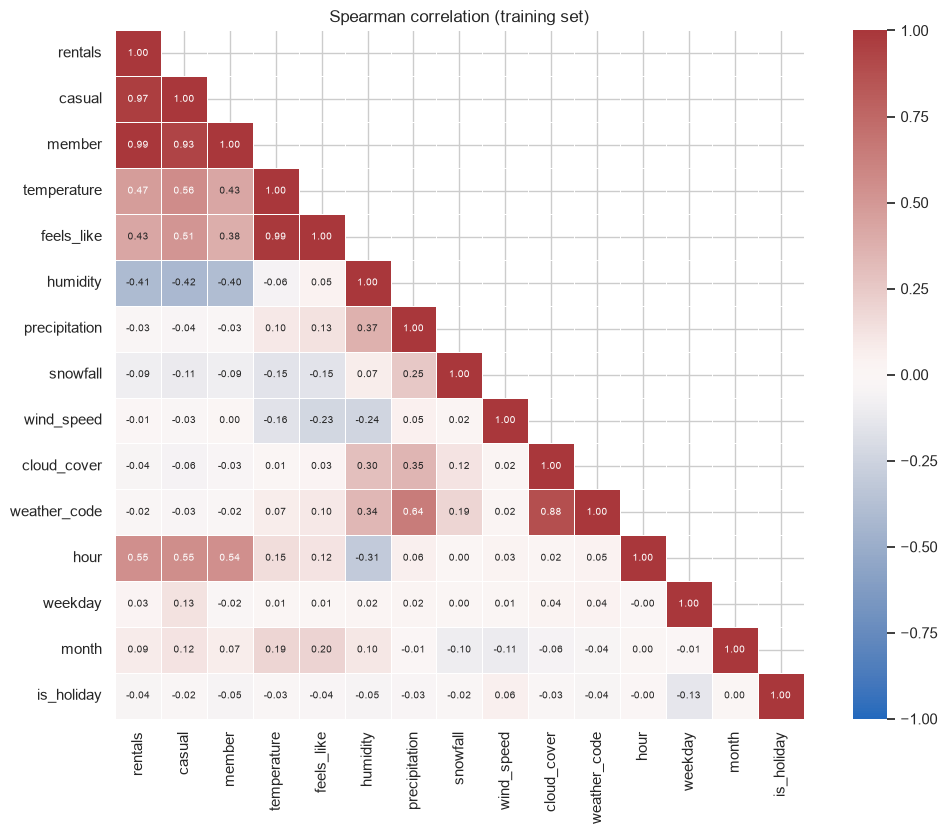

,,spearman
temperature,feels_like,0.991
cloud_cover,weather_code,0.882
precipitation,weather_code,0.642


In [18]:
corr_cols = num_cols + ["weather_code", "hour", "weekday", "month", "is_holiday"]
corr = train[corr_cols].corr(method="spearman")  # rank-based: robust to skewed and zero-inflated features

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
            annot_kws={"size": 7}, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Spearman correlation (training set)")
plt.tight_layout()
plt.show()

# Feature pairs (target and its parts excluded) with |rho| > 0.5
features = [c for c in corr_cols if c not in ["rentals", "casual", "member"]]
pairs = corr.loc[features, features].where(np.triu(np.ones((len(features), len(features)), dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(3).rename("spearman").to_frame()

**Finding:** `temperature` ≈ `feels_like` (ρ = 0.99) → keep only one for the linear model. `weather_code` overlaps with `cloud_cover` and `precipitation`.

**Next question:** Correlation only sees monotonic relationships, but `hour` has two peaks. → mutual information.

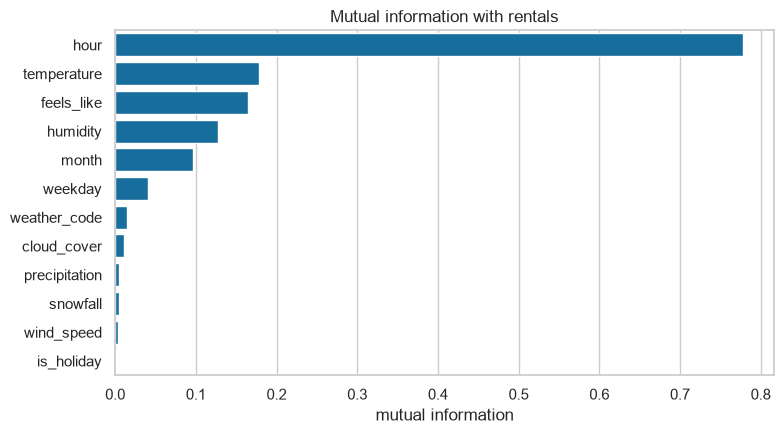

feature,hour,temperature,feels_like,humidity,month,weekday,weather_code,cloud_cover,precipitation,snowfall,wind_speed,is_holiday
mutual_information,0.778,0.178,0.165,0.128,0.097,0.041,0.014,0.012,0.005,0.004,0.003,0.001
spearman_with_rentals,0.547,0.474,0.428,-0.411,0.085,0.028,-0.024,-0.042,-0.030,-0.093,-0.008,-0.043


In [19]:
# Features available before the hour is counted (casual and member excluded)
candidates = ["hour", "weekday", "month", "is_holiday", "weather_code"] + weather_num
discrete = [c in ["hour", "weekday", "month", "is_holiday", "weather_code"] for c in candidates]
mi = mutual_info_regression(train[candidates], train["rentals"], discrete_features=discrete, random_state=42)

relevance = pd.DataFrame({
    "feature": candidates,
    "mutual_information": mi,
    "spearman_with_rentals": train[candidates].corrwith(train["rentals"], method="spearman").values,
}).sort_values("mutual_information", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=relevance, y="feature", x="mutual_information", ax=ax)
ax.set(title="Mutual information with rentals", xlabel="mutual information", ylabel="")
plt.tight_layout()
plt.show()

relevance.round(3).set_index("feature").T

**Finding:** `hour` is by far the most informative feature (strong but non-monotonic), followed by temperature, humidity and `month`. The day type adds little on average but changes the *shape* of the daily pattern (iteration 4).

**Last check:** leakage.

In [20]:
print("rentals == casual + member in every row:", (train["rentals"] == train["casual"] + train["member"]).all())
train[["casual", "member", "rentals"]].corr(method="spearman").round(3)

rentals == casual + member in every row: True


,casual,member,rentals
casual,1.000,0.932,0.967
member,0.932,1.000,0.993
rentals,0.967,0.993,1.000


**Finding:** `casual` and `member` are **parts of the target**, only known after the hour is counted → **↺** dropped in `prepare_data`.

## 7. Summary

| Iteration | Finding | Action |
|:--|:--|:--|
| 1 Data quality | `holiday` structurally missing; no duplicates/gaps; values valid | ↺ `is_holiday`, `day_type` |
| 1 Data quality | DST hours corrupt (0 rentals / doubled hour) | ↺ `remove_dst_artifacts`, also on the test set |
| 2 Distributions | Target right-skewed; precipitation/snow zero-inflated; rare weather codes | Test `log1p` target; ↺ `weather_group` |
| 3 Outliers | Global IQR rule unsuitable; contextual outliers are event nights and snow/cold days | Keep them (real events) |
| 4 Time & weather | Commuter peaks vs. midday hump; strong season; temperature non-linear, rain/snow lower rentals | `hour` × `day_type` interaction; use `month` and weather |
| 5 Correlations | `temperature` ≈ `feels_like`; `hour` most informative | One temperature feature for the linear model |
| 5 Leakage | `casual` + `member` = target | ↺ dropped in `prepare_data` |

**For the project notebook:** copy `nth_sunday`, `dst_artifact_hours`, `remove_dst_artifacts`, `WEATHER_GROUPS`, `add_features` and `prepare_data`, call `prepare_data(df_train)` before step 4 and `prepare_data(df_test)` in step 8.